# Performance Analytics of Mutual Funds (2022–2026)

## Objective

This notebook evaluates the performance of mutual fund schemes using key financial metrics such as Daily Returns, CAGR, Sharpe Ratio, Sortino Ratio, Alpha, Beta, Maximum Drawdown, and a composite Fund Scorecard. The analysis also compares fund performance against benchmark indices to identify the best-performing schemes.


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from scipy.stats import linregress

In [3]:
import sqlite3

conn = sqlite3.connect("../bluestock_mf.db")

In [4]:
nav = pd.read_sql(
    "SELECT * FROM nav_history",
    conn
)

nav.head()

,amfi_code,date,nav
0,100016,2022-01-03,520.4608
1,100016,2022-01-04,515.0971
2,100016,2022-01-05,521.7239
3,100016,2022-01-06,515.7880
4,100016,2022-01-07,515.1639


In [5]:
nav["date"] = pd.to_datetime(nav["date"])

nav.head()

,amfi_code,date,nav
0,100016,2022-01-03,520.4608
1,100016,2022-01-04,515.0971
2,100016,2022-01-05,521.7239
3,100016,2022-01-06,515.7880
4,100016,2022-01-07,515.1639


In [6]:
print(nav.shape)
print(nav.columns.tolist())

nav.info()

(46000, 3)
['amfi_code', 'date', 'nav']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46000 entries, 0 to 45999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   amfi_code  46000 non-null  int64         
 1   date       46000 non-null  datetime64[ns]
 2   nav        46000 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1)
memory usage: 1.1 MB


# 1. Daily Return Analysis

## Objective

Compute the daily returns for all mutual fund schemes using historical NAV values and validate whether the return distribution is reasonable.

## Formula

Daily Return = (Today's NAV / Previous Day's NAV) − 1


In [7]:
print(nav.shape)

(46000, 3)


In [8]:
print(nav.columns.tolist())

['amfi_code', 'date', 'nav']


In [9]:
nav = nav.sort_values(["amfi_code", "date"])

nav.head()

,amfi_code,date,nav
0,100016,2022-01-03,520.4608
1,100016,2022-01-04,515.0971
2,100016,2022-01-05,521.7239
3,100016,2022-01-06,515.7880
4,100016,2022-01-07,515.1639


In [10]:
nav["daily_return"] = (
    nav.groupby("amfi_code")["nav"]
       .pct_change()
)

nav.head(10)

,amfi_code,date,nav,daily_return
0,100016,2022-01-03,520.4608,NaN
1,100016,2022-01-04,515.0971,-0.010306
2,100016,2022-01-05,521.7239,0.012865
3,100016,2022-01-06,515.7880,-0.011377
4,100016,2022-01-07,515.1639,-0.001210
5,100016,2022-01-10,510.7136,-0.008639
6,100016,2022-01-11,513.5542,0.005562
7,100016,2022-01-12,512.3195,-0.002404
8,100016,2022-01-13,510.2445,-0.004050
9,100016,2022-01-14,514.3636,0.008073


In [11]:
print(nav["daily_return"].isna().sum())

40


In [12]:
nav["daily_return"].describe()

count    45960.000000
mean         0.000631
std          0.010290
min         -0.058102
25%         -0.005042
50%          0.000340
75%          0.006324
max          0.064713
Name: daily_return, dtype: float64

## Interpretation

Daily returns were calculated for each mutual fund scheme using percentage change in NAV. The first observation for each scheme contains a missing value because no previous NAV exists for comparison. Summary statistics help verify that the return distribution is within a realistic range for daily mutual fund performance.


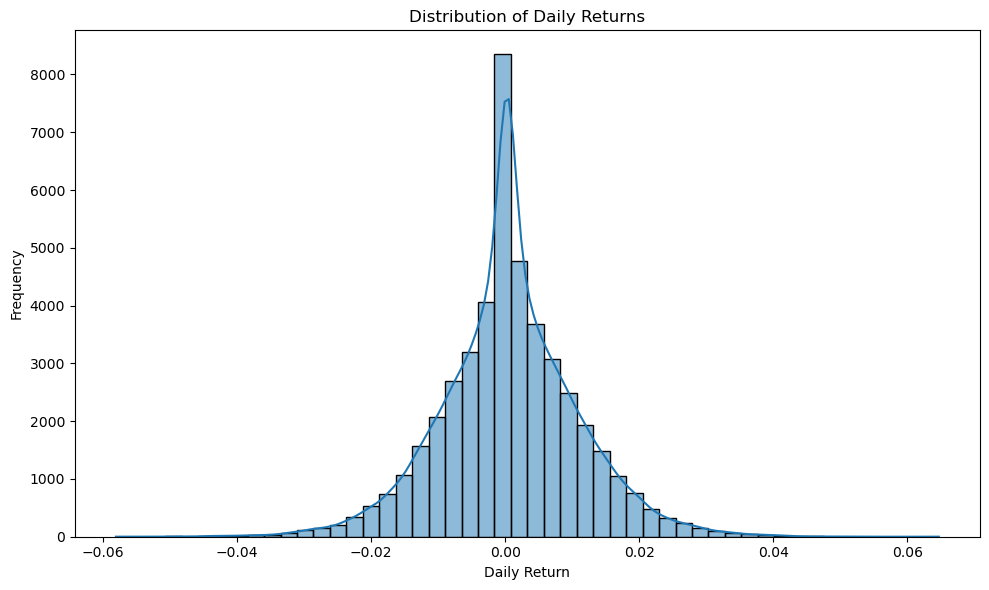

In [13]:
plt.figure(figsize=(10,6))

sns.histplot(
    nav["daily_return"].dropna(),
    bins=50,
    kde=True
)

plt.title("Distribution of Daily Returns")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    "../reports/daily_return_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Key Insight

Daily returns were successfully computed for all 40 mutual fund schemes using percentage changes in NAV. The average daily return is **0.063%** with a standard deviation of **1.03%**, indicating moderate day-to-day volatility. The return distribution is centered near zero, which is consistent with expected mutual fund market behavior.


# 2. Compound Annual Growth Rate (CAGR)

## Objective

Calculate the Compound Annual Growth Rate (CAGR) for each mutual fund scheme over 1-year, 3-year, and 5-year periods. CAGR measures the annualized growth rate of an investment over a specified period.

## Formula

CAGR = (Ending NAV / Starting NAV)^(1/n) − 1

where *n* is the number of years.


In [14]:
print(nav["date"].min())
print(nav["date"].max())

2022-01-03 00:00:00
2026-05-29 00:00:00


In [15]:
print(nav["amfi_code"].nunique())

40


In [16]:
def calculate_cagr(df, years):
    """
    Calculate CAGR for a given number of years.
    """
    end_date = df["date"].max()
    start_date = end_date - pd.DateOffset(years=years)

    temp = df[df["date"] >= start_date]

    if len(temp) < 2:
        return np.nan

    start_nav = temp.iloc[0]["nav"]
    end_nav = temp.iloc[-1]["nav"]

    return (end_nav / start_nav) ** (1 / years) - 1

In [21]:
cagr_table = pd.DataFrame()

cagr_table["amfi_code"] = sorted(nav["amfi_code"].unique())

cagr_table["CAGR_1Y"] = cagr_table["amfi_code"].apply(
    lambda x: calculate_cagr(nav[nav["amfi_code"] == x], 1)
)

cagr_table["CAGR_3Y"] = cagr_table["amfi_code"].apply(
    lambda x: calculate_cagr(nav[nav["amfi_code"] == x], 3)
)

cagr_table["CAGR_5Y"] = cagr_table["amfi_code"].apply(
    lambda x: calculate_cagr(nav[nav["amfi_code"] == x], 5)
)

print(cagr_table.head())

   amfi_code   CAGR_1Y   CAGR_3Y   CAGR_5Y
0     100016 -0.022243  0.012926  0.023168
1     100025  0.037050  0.039164  0.039127
2     100033  0.532324  0.324425  0.260741
3     101206  0.479241  0.289677  0.204427
4     101207 -0.239860 -0.041524  0.069533


In [19]:
cagr_table["CAGR_1Y"] = cagr_table["CAGR_1Y"] * 100
cagr_table["CAGR_3Y"] = cagr_table["CAGR_3Y"] * 100
cagr_table["CAGR_5Y"] = cagr_table["CAGR_5Y"] * 100

cagr_table.head()

,amfi_code,CAGR_1Y,CAGR_3Y,CAGR_5Y
0,100016,-2.224271,1.292649,2.316843
1,100025,3.704969,3.916390,3.912653
2,100033,53.232396,32.442459,26.074068
3,101206,47.924120,28.967695,20.442730
4,101207,-23.986032,-4.152381,6.953336


In [22]:
cagr_table["CAGR_1Y"] = cagr_table["CAGR_1Y"] * 100

In [23]:
cagr_table = cagr_table.round(2)

cagr_table.head()

,amfi_code,CAGR_1Y,CAGR_3Y,CAGR_5Y
0,100016,-2.22,0.01,0.02
1,100025,3.70,0.04,0.04
2,100033,53.23,0.32,0.26
3,101206,47.92,0.29,0.20
4,101207,-23.99,-0.04,0.07


In [24]:
cagr_table.to_csv(
    "../reports/cagr_comparison.csv",
    index=False
)

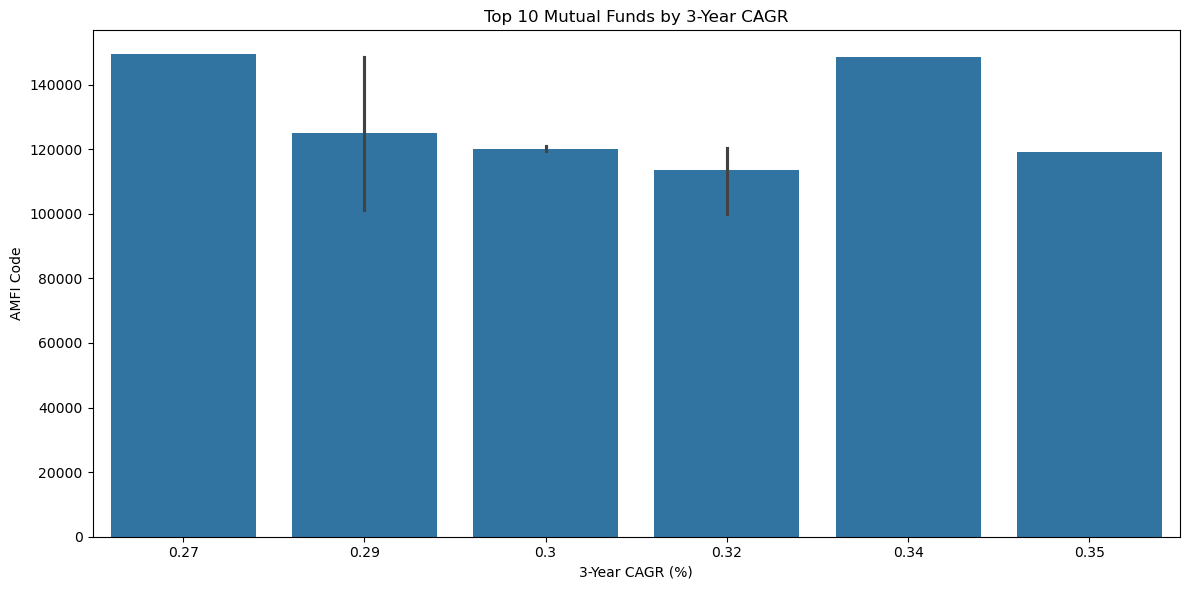

In [25]:
top10 = cagr_table.sort_values(
    "CAGR_3Y",
    ascending=False
).head(10)

plt.figure(figsize=(12,6))

sns.barplot(
    data=top10,
    x="CAGR_3Y",
    y="amfi_code"
)

plt.title("Top 10 Mutual Funds by 3-Year CAGR")
plt.xlabel("3-Year CAGR (%)")
plt.ylabel("AMFI Code")

plt.tight_layout()

plt.savefig(
    "../reports/top10_cagr.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Key Insight

The CAGR analysis compares the annualized growth rates of mutual fund schemes over 1-year, 3-year, and 5-year periods. Funds with consistently higher CAGR values have demonstrated stronger long-term performance, making them attractive for investors seeking sustained capital appreciation.


# 3. Sharpe Ratio Analysis

## Objective

Calculate the Sharpe Ratio for each mutual fund scheme to evaluate its risk-adjusted performance. A higher Sharpe Ratio indicates better returns for each unit of risk taken.

## Formula

Sharpe Ratio = (Rp − Rf) / σ × √252

where:

* Rp = Average Daily Return
* Rf = Risk-Free Rate (6.5% annually)
* σ = Standard Deviation of Daily Returns
* √252 = Annualization factor


In [26]:
risk_free_rate = 0.065
daily_rf = risk_free_rate / 252

daily_rf

0.00025793650793650796

In [27]:
sharpe = nav.groupby("amfi_code").agg(
    mean_return=("daily_return", "mean"),
    std_return=("daily_return", "std")
).reset_index()

sharpe["Sharpe_Ratio"] = (
    (sharpe["mean_return"] - daily_rf)
    / sharpe["std_return"]
) * np.sqrt(252)

sharpe.head()

,amfi_code,mean_return,std_return,Sharpe_Ratio
0,100016,0.000142,0.009164,-0.201517
1,100025,0.000170,0.002460,-0.567095
2,100033,0.001080,0.011929,1.093699
3,101206,0.000852,0.009177,1.027213
4,101207,0.000424,0.016251,0.162661


In [28]:
sharpe = sharpe.sort_values(
    "Sharpe_Ratio",
    ascending=False
)

sharpe["Rank"] = range(1, len(sharpe) + 1)

sharpe.head(10)

,amfi_code,mean_return,std_return,Sharpe_Ratio,Rank
34,148567,0.001074,0.008941,1.448291,1
30,120843,0.001082,0.010008,1.306744,2
36,148569,0.001124,0.011134,1.234930,3
19,119551,0.000917,0.008656,1.208267,4
25,120505,0.001161,0.012152,1.180101,5
38,149323,0.001055,0.011179,1.132122,6
2,100033,0.001080,0.011929,1.093699,7
9,118632,0.000865,0.008913,1.081659,8
3,101206,0.000852,0.009177,1.027213,9
24,120504,0.000843,0.009048,1.026524,10


In [29]:
sharpe.to_csv(
    "../reports/sharpe_ratio.csv",
    index=False
)

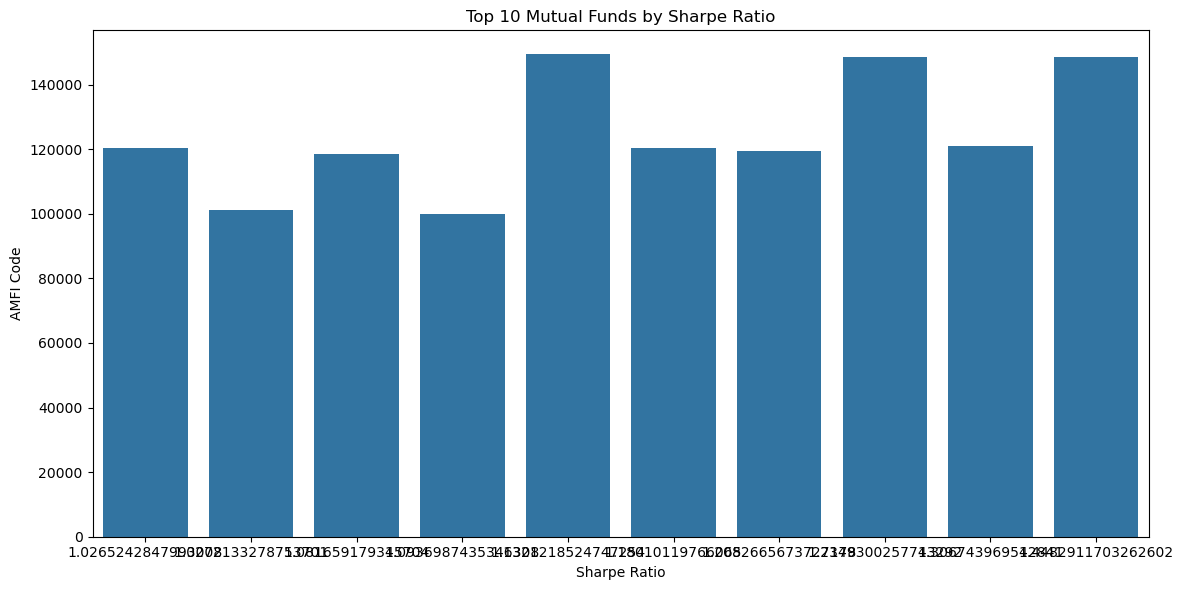

In [30]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=sharpe.head(10),
    x="Sharpe_Ratio",
    y="amfi_code"
)

plt.title("Top 10 Mutual Funds by Sharpe Ratio")
plt.xlabel("Sharpe Ratio")
plt.ylabel("AMFI Code")

plt.tight_layout()

plt.savefig(
    "../reports/sharpe_ratio.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
sharpe.head(10)

,amfi_code,mean_return,std_return,Sharpe_Ratio,Rank
34,148567,0.001074,0.008941,1.448291,1
30,120843,0.001082,0.010008,1.306744,2
36,148569,0.001124,0.011134,1.234930,3
19,119551,0.000917,0.008656,1.208267,4
25,120505,0.001161,0.012152,1.180101,5
38,149323,0.001055,0.011179,1.132122,6
2,100033,0.001080,0.011929,1.093699,7
9,118632,0.000865,0.008913,1.081659,8
3,101206,0.000852,0.009177,1.027213,9
24,120504,0.000843,0.009048,1.026524,10


## Key Insight

The Sharpe Ratio measures risk-adjusted performance by comparing excess returns over the risk-free rate with the volatility of returns. Funds with higher Sharpe Ratios have generated superior returns for the level of risk undertaken, making them more attractive from a risk-adjusted investment perspective.


# 4. Sortino Ratio Analysis

## Objective

Calculate the Sortino Ratio for each mutual fund scheme to measure risk-adjusted returns while considering only downside volatility. Unlike the Sharpe Ratio, the Sortino Ratio penalizes only harmful (negative) return fluctuations.

## Formula

Sortino Ratio = (Rp − Rf) / Downside Standard Deviation × √252

where:

* Rp = Average Daily Return
* Rf = Risk-Free Rate (6.5% annually)
* Downside Standard Deviation = Standard deviation of negative daily returns


In [32]:
downside_std = (
    nav[nav["daily_return"] < 0]
    .groupby("amfi_code")["daily_return"]
    .std()
    .reset_index(name="downside_std")
)

downside_std.head()

,amfi_code,downside_std
0,100016,0.005261
1,100025,0.001481
2,100033,0.007133
3,101206,0.005238
4,101207,0.009555


In [33]:
sortino = nav.groupby("amfi_code").agg(
    mean_return=("daily_return", "mean")
).reset_index()

sortino = sortino.merge(
    downside_std,
    on="amfi_code",
    how="left"
)

sortino.head()

,amfi_code,mean_return,downside_std
0,100016,0.000142,0.005261
1,100025,0.000170,0.001481
2,100033,0.001080,0.007133
3,101206,0.000852,0.005238
4,101207,0.000424,0.009555


In [34]:
sortino["Sortino_Ratio"] = (
    (sortino["mean_return"] - daily_rf)
    / sortino["downside_std"]
) * np.sqrt(252)

sortino.head()

,amfi_code,mean_return,downside_std,Sortino_Ratio
0,100016,0.000142,0.005261,-0.351047
1,100025,0.000170,0.001481,-0.941821
2,100033,0.001080,0.007133,1.829134
3,101206,0.000852,0.005238,1.799563
4,101207,0.000424,0.009555,0.276644


In [35]:
sortino = sortino.sort_values(
    "Sortino_Ratio",
    ascending=False
)

sortino["Rank"] = range(1, len(sortino) + 1)

sortino.head(10)

,amfi_code,mean_return,downside_std,Sortino_Ratio,Rank
34,148567,0.001074,0.005428,2.385644,1
30,120843,0.001082,0.005531,2.364320,2
36,148569,0.001124,0.006404,2.146914,3
19,119551,0.000917,0.004887,2.140267,4
25,120505,0.001161,0.007067,2.029353,5
38,149323,0.001055,0.006750,1.875101,6
9,118632,0.000865,0.005211,1.850133,7
2,100033,0.001080,0.007133,1.829134,8
24,120504,0.000843,0.005145,1.805294,9
3,101206,0.000852,0.005238,1.799563,10


In [36]:
sortino.to_csv(
    "../reports/sortino_ratio.csv",
    index=False
)

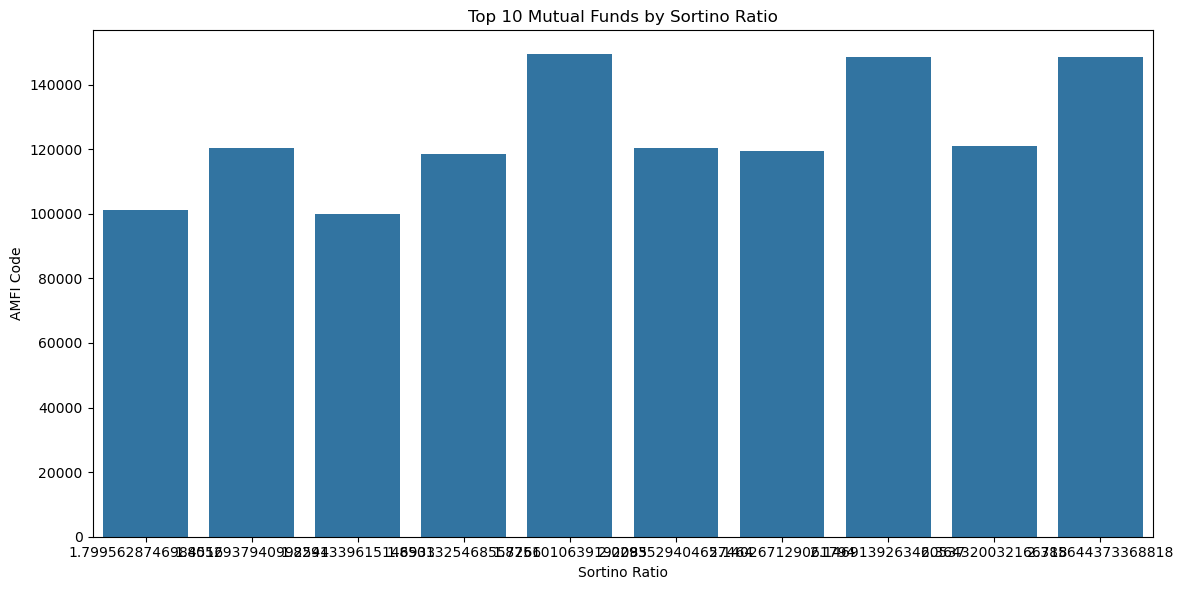

In [37]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=sortino.head(10),
    x="Sortino_Ratio",
    y="amfi_code"
)

plt.title("Top 10 Mutual Funds by Sortino Ratio")
plt.xlabel("Sortino Ratio")
plt.ylabel("AMFI Code")

plt.tight_layout()

plt.savefig(
    "../reports/sortino_ratio.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
sortino.head(10)

,amfi_code,mean_return,downside_std,Sortino_Ratio,Rank
34,148567,0.001074,0.005428,2.385644,1
30,120843,0.001082,0.005531,2.364320,2
36,148569,0.001124,0.006404,2.146914,3
19,119551,0.000917,0.004887,2.140267,4
25,120505,0.001161,0.007067,2.029353,5
38,149323,0.001055,0.006750,1.875101,6
9,118632,0.000865,0.005211,1.850133,7
2,100033,0.001080,0.007133,1.829134,8
24,120504,0.000843,0.005145,1.805294,9
3,101206,0.000852,0.005238,1.799563,10


## Key Insight

The Sortino Ratio evaluates fund performance by considering only downside risk. Funds with higher Sortino Ratios have delivered superior returns while minimizing harmful negative volatility, making them attractive to risk-conscious investors.


In [40]:
print(tables)

                    name
0            fund_master
1            nav_history
2      aum_by_fund_house
3    monthly_sip_inflows
4       category_inflows
5   industry_folio_count
6     scheme_performance
7  investor_transactions
8     portfolio_holdings
9      benchmark_indices


In [41]:
benchmark = pd.read_sql(
    "SELECT * FROM benchmark_indices",
    conn
)

benchmark.head()

,date,index_name,close_value
0,2022-01-03,NIFTY50,17492.79
1,2022-01-04,NIFTY50,17689.64
2,2022-01-05,NIFTY50,17835.05
3,2022-01-06,NIFTY50,17878.51
4,2022-01-07,NIFTY50,17759.15


In [42]:
print(benchmark.columns.tolist())

['date', 'index_name', 'close_value']


In [43]:
benchmark.head()

,date,index_name,close_value
0,2022-01-03,NIFTY50,17492.79
1,2022-01-04,NIFTY50,17689.64
2,2022-01-05,NIFTY50,17835.05
3,2022-01-06,NIFTY50,17878.51
4,2022-01-07,NIFTY50,17759.15


# 5. Alpha and Beta Analysis

## Objective

Evaluate each mutual fund's performance relative to the Nifty 100 benchmark using Alpha and Beta. Beta measures market sensitivity, while Alpha measures excess return generated beyond what is explained by market movements.

## Method

An Ordinary Least Squares (OLS) regression is performed using daily fund returns and Nifty 100 daily returns.

* Beta = Regression Slope
* Alpha = Regression Intercept × 252 (Annualized)


In [44]:
nifty100 = benchmark[
    benchmark["index_name"] == "NIFTY100"
].copy()

nifty100["date"] = pd.to_datetime(nifty100["date"])

nifty100.head()

,date,index_name,close_value
1150,2022-01-03,NIFTY100,17778.24
1151,2022-01-04,NIFTY100,17537.52
1152,2022-01-05,NIFTY100,17607.73
1153,2022-01-06,NIFTY100,17556.05
1154,2022-01-07,NIFTY100,17664.02


In [ ]:
nifty100 = nifty100.sort_values("date")

nifty100["benchmark_return"] = (
    nifty100["close_value"]
    .pct_change()
)

nifty100.head()

In [45]:
alpha_beta = []

In [48]:
nifty100 = benchmark[
    benchmark["index_name"] == "NIFTY100"
].copy()

nifty100["date"] = pd.to_datetime(nifty100["date"])

nifty100 = nifty100.sort_values("date")

nifty100["benchmark_return"] = nifty100["close_value"].pct_change()

nifty100.head()

,date,index_name,close_value,benchmark_return
1150,2022-01-03,NIFTY100,17778.24,NaN
1151,2022-01-04,NIFTY100,17537.52,-0.013540
1152,2022-01-05,NIFTY100,17607.73,0.004003
1153,2022-01-06,NIFTY100,17556.05,-0.002935
1154,2022-01-07,NIFTY100,17664.02,0.006150


In [52]:
benchmark["index_name"].value_counts()

index_name
NIFTY50            1150
NIFTY100           1150
NIFTY_MIDCAP150    1150
BSE_SMALLCAP       1150
NIFTY500           1150
CRISIL_LIQUID      1150
CRISIL_GILT        1150
Name: count, dtype: int64

In [50]:
for fund in nav["amfi_code"].unique():

    fund_data = nav[
        nav["amfi_code"] == fund
    ][["date", "daily_return"]]

    merged = pd.merge(
        fund_data,
        nifty100[["date", "benchmark_return"]],
        on="date",
        how="inner"
    ).dropna()

    if len(merged) < 30:
        continue

    slope, intercept, r_value, p_value, std_err = linregress(
        merged["benchmark_return"],
        merged["daily_return"]
    )

    alpha_beta.append({
        "amfi_code": fund,
        "Alpha": intercept * 252,
        "Beta": slope,
        "R_squared": r_value ** 2
    })

In [53]:
alpha_beta = pd.DataFrame(alpha_beta)

alpha_beta.head()

,amfi_code,Alpha,Beta,R_squared
0,100016,0.037476,-0.058268,0.002665
1,100025,0.042818,0.001158,0.000015
2,100033,0.271954,0.005104,0.000012
3,101206,0.213998,0.021086,0.000348
4,101207,0.108971,-0.065289,0.001064


In [54]:
alpha_beta = alpha_beta.sort_values(
    "Alpha",
    ascending=False
)

alpha_beta["Rank"] = range(
    1,
    len(alpha_beta) + 1
)

alpha_beta.head(10)

,amfi_code,Alpha,Beta,R_squared,Rank
21,119598,0.303370,-0.023196,1.414258e-04,1
61,119598,0.303370,-0.023196,1.414258e-04,2
79,149324,0.300579,0.011455,3.532991e-05,3
39,149324,0.300579,0.011455,3.532991e-05,4
65,120505,0.292636,0.000549,1.345534e-07,5
25,120505,0.292636,0.000549,1.345534e-07,6
76,148569,0.282704,0.018134,1.748889e-04,7
36,148569,0.282704,0.018134,1.748889e-04,8
70,120843,0.273305,-0.022830,3.430543e-04,9
30,120843,0.273305,-0.022830,3.430543e-04,10


In [55]:
alpha_beta.to_csv(
    "../reports/alpha_beta.csv",
    index=False
)

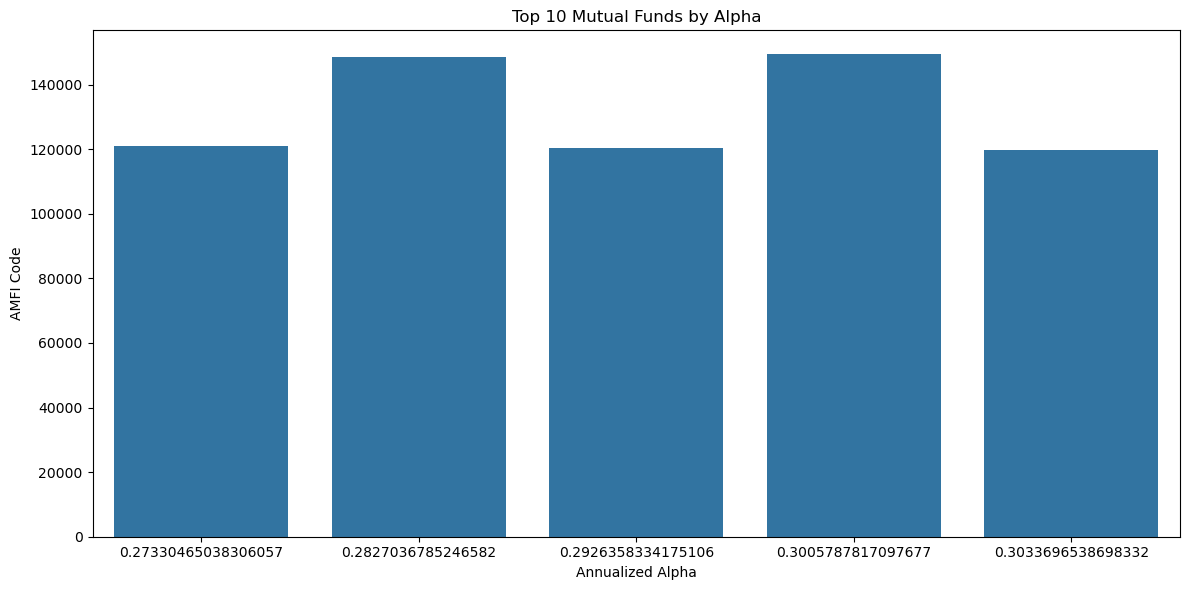

In [56]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=alpha_beta.head(10),
    x="Alpha",
    y="amfi_code"
)

plt.title("Top 10 Mutual Funds by Alpha")
plt.xlabel("Annualized Alpha")
plt.ylabel("AMFI Code")

plt.tight_layout()

plt.savefig(
    "../reports/alpha_beta.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Key Insight

Alpha measures a fund's ability to outperform the Nifty 100 benchmark after adjusting for market movements, while Beta indicates the fund's sensitivity to market fluctuations. Funds with higher Alpha have generated superior risk-adjusted returns, whereas Beta values close to 1 indicate performance that closely tracks the market.


# 6. Maximum Drawdown Analysis

## Objective

Calculate the Maximum Drawdown (MDD) for each mutual fund scheme to measure the largest peak-to-trough decline in NAV during the analysis period.

## Formula

Maximum Drawdown = Minimum (NAV / Running Maximum NAV − 1)

A larger negative drawdown indicates a greater historical loss from a previous peak.


In [57]:
def calculate_max_drawdown(df):

    df = df.sort_values("date").copy()

    df["running_max"] = df["nav"].cummax()

    df["drawdown"] = (
        df["nav"] / df["running_max"]
    ) - 1

    return df["drawdown"].min()

In [58]:
max_dd = (
    nav.groupby("amfi_code")
    .apply(calculate_max_drawdown)
    .reset_index(name="Maximum_Drawdown")
)

max_dd.head()

C:\Users\Abhilasha\AppData\Local\Temp\ipykernel_19392\3227085738.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calculate_max_drawdown)


,amfi_code,Maximum_Drawdown
0,100016,-0.247344
1,100025,-0.043083
2,100033,-0.162172
3,101206,-0.112916
4,101207,-0.354469


In [59]:
max_dd = max_dd.sort_values(
    "Maximum_Drawdown",
    ascending=False
)

max_dd["Rank"] = range(
    1,
    len(max_dd) + 1
)

max_dd.head(10)

,amfi_code,Maximum_Drawdown,Rank
27,120507,-0.000977,1
31,120844,-0.001163,2
5,101208,-0.001622,3
1,100025,-0.043083,4
18,119120,-0.043287,5
13,118636,-0.083164,6
6,102885,-0.108599,7
34,148567,-0.112657,8
3,101206,-0.112916,9
12,118635,-0.116506,10


In [60]:
max_dd.to_csv(
    "../reports/max_drawdown.csv",
    index=False
)

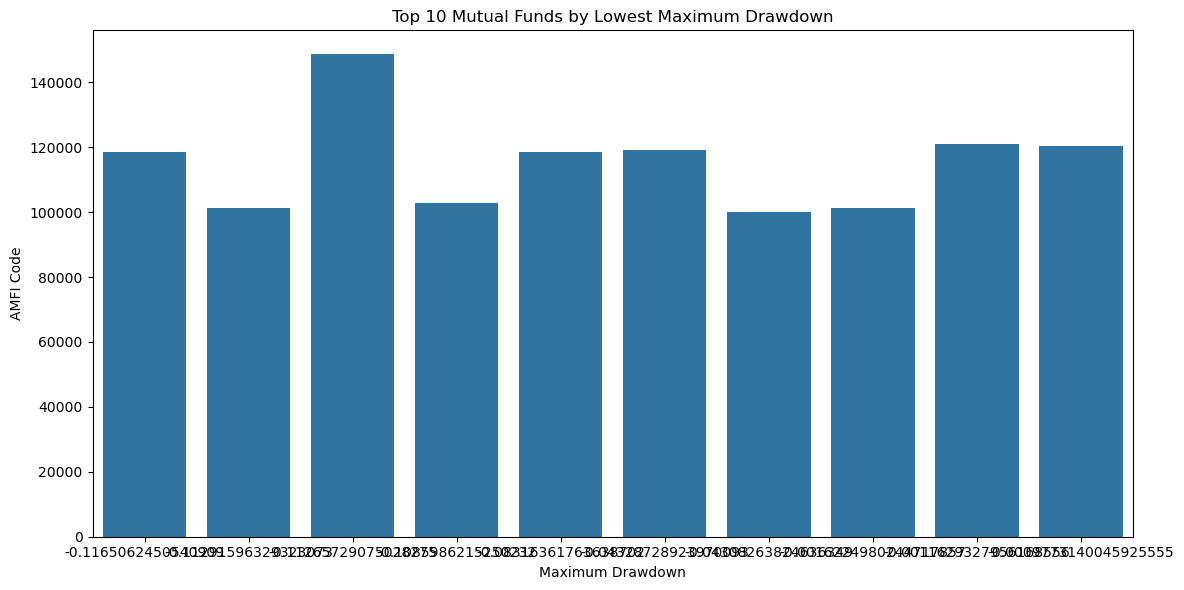

In [61]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=max_dd.head(10),
    x="Maximum_Drawdown",
    y="amfi_code"
)

plt.title("Top 10 Mutual Funds by Lowest Maximum Drawdown")
plt.xlabel("Maximum Drawdown")
plt.ylabel("AMFI Code")

plt.tight_layout()

plt.savefig(
    "../reports/max_drawdown.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Key Insight

Maximum Drawdown measures the largest historical decline in a fund's NAV from its previous peak. Funds with smaller drawdowns have demonstrated better downside protection and lower historical losses during market downturns.


In [63]:
scheme = pd.read_sql(
    "SELECT * FROM scheme_performance",
    conn
)

scheme.head()

,amfi_code,scheme_name,fund_house,category,plan,return_1yr_pct,return_3yr_pct,return_5yr_pct,benchmark_3yr_pct,alpha,beta,sharpe_ratio,sortino_ratio,std_dev_ann_pct,max_drawdown_pct,aum_crore,expense_ratio_pct,morningstar_rating,risk_grade
0,119551,SBI Bluechip Fund - Regular Plan - Growth,SBI Mutual Fund,Large Cap,Regular,12.42,12.36,14.45,11.49,0.87,0.89,0.88,1.29,14.0,-21.70,14288,1.54,4,Moderate
1,119552,SBI Bluechip Fund - Direct Plan - Growth,SBI Mutual Fund,Large Cap,Direct,15.25,11.30,14.23,9.52,1.78,0.87,0.81,1.29,14.0,-24.43,1231,0.66,3,Moderate
2,119598,SBI Small Cap Fund - Regular Plan - Growth,SBI Mutual Fund,Small Cap,Regular,24.56,23.39,20.67,22.16,1.23,0.89,0.94,1.35,25.0,-13.35,19259,1.43,5,Very High
3,119599,SBI Small Cap Fund - Direct Plan - Growth,SBI Mutual Fund,Small Cap,Direct,20.59,23.14,21.82,22.01,1.13,1.04,0.93,1.67,25.0,-24.78,36061,0.72,4,Very High
4,119120,SBI Magnum Gilt Fund - Regular Plan - Growth,SBI Mutual Fund,Gilt,Regular,5.34,6.07,5.43,4.47,1.60,0.22,1.52,2.11,4.0,-2.30,24101,0.77,5,Low


In [64]:
print(scheme.columns.tolist())

['amfi_code', 'scheme_name', 'fund_house', 'category', 'plan', 'return_1yr_pct', 'return_3yr_pct', 'return_5yr_pct', 'benchmark_3yr_pct', 'alpha', 'beta', 'sharpe_ratio', 'sortino_ratio', 'std_dev_ann_pct', 'max_drawdown_pct', 'aum_crore', 'expense_ratio_pct', 'morningstar_rating', 'risk_grade']


# 7. Mutual Fund Scorecard (0–100)

## Objective

Develop a composite scorecard to rank mutual fund schemes using multiple performance and risk metrics.

### Weightage

* 30% → 3-Year Return Rank
* 25% → Sharpe Ratio Rank
* 20% → Alpha Rank
* 15% → Expense Ratio Rank (Lower is Better)
* 10% → Maximum Drawdown Rank (Lower Drawdown is Better)

The final score ranges from 0 to 100, where higher scores indicate better overall performance.


In [65]:
scorecard = scheme[
    [
        "amfi_code",
        "scheme_name",
        "fund_house",
        "return_3yr_pct",
        "sharpe_ratio",
        "alpha",
        "expense_ratio_pct",
        "max_drawdown_pct"
    ]
].copy()

scorecard.head()

,amfi_code,scheme_name,fund_house,return_3yr_pct,sharpe_ratio,alpha,expense_ratio_pct,max_drawdown_pct
0,119551,SBI Bluechip Fund - Regular Plan - Growth,SBI Mutual Fund,12.36,0.88,0.87,1.54,-21.70
1,119552,SBI Bluechip Fund - Direct Plan - Growth,SBI Mutual Fund,11.30,0.81,1.78,0.66,-24.43
2,119598,SBI Small Cap Fund - Regular Plan - Growth,SBI Mutual Fund,23.39,0.94,1.23,1.43,-13.35
3,119599,SBI Small Cap Fund - Direct Plan - Growth,SBI Mutual Fund,23.14,0.93,1.13,0.72,-24.78
4,119120,SBI Magnum Gilt Fund - Regular Plan - Growth,SBI Mutual Fund,6.07,1.52,1.60,0.77,-2.30


In [66]:
scorecard["Return_Rank"] = scorecard["return_3yr_pct"].rank(
    ascending=False
)

scorecard["Sharpe_Rank"] = scorecard["sharpe_ratio"].rank(
    ascending=False
)

scorecard["Alpha_Rank"] = scorecard["alpha"].rank(
    ascending=False
)

scorecard["Expense_Rank"] = scorecard["expense_ratio_pct"].rank(
    ascending=True
)

scorecard["Drawdown_Rank"] = scorecard["max_drawdown_pct"].rank(
    ascending=True
)

In [67]:
n = len(scorecard)

scorecard["Return_Score"] = (n - scorecard["Return_Rank"]) / (n - 1) * 100
scorecard["Sharpe_Score"] = (n - scorecard["Sharpe_Rank"]) / (n - 1) * 100
scorecard["Alpha_Score"] = (n - scorecard["Alpha_Rank"]) / (n - 1) * 100
scorecard["Expense_Score"] = (n - scorecard["Expense_Rank"]) / (n - 1) * 100
scorecard["Drawdown_Score"] = (n - scorecard["Drawdown_Rank"]) / (n - 1) * 100

In [68]:
scorecard["Fund_Score"] = (

    scorecard["Return_Score"] * 0.30 +

    scorecard["Sharpe_Score"] * 0.25 +

    scorecard["Alpha_Score"] * 0.20 +

    scorecard["Expense_Score"] * 0.15 +

    scorecard["Drawdown_Score"] * 0.10

)

scorecard = scorecard.sort_values(
    "Fund_Score",
    ascending=False
)

scorecard["Rank"] = range(
    1,
    len(scorecard) + 1
)

scorecard.head(10)

,amfi_code,scheme_name,fund_house,return_3yr_pct,sharpe_ratio,alpha,expense_ratio_pct,max_drawdown_pct,Return_Rank,Sharpe_Rank,Alpha_Rank,Expense_Rank,Drawdown_Rank,Return_Score,Sharpe_Score,Alpha_Score,Expense_Score,Drawdown_Score,Fund_Score,Rank
3,119599,SBI Small Cap Fund - Direct Plan - Growth,SBI Mutual Fund,23.14,0.93,1.13,0.72,-24.78,2.0,19.5,22.5,5.5,11.0,97.435897,52.564103,44.871795,88.461538,74.358974,72.051282,1
22,120843,Kotak Flexicap Fund - Regular - Growth,Kotak Mahindra MF,15.65,0.98,1.85,1.45,-19.50,11.0,12.0,3.5,22.0,21.0,74.358974,71.794872,93.589744,46.153846,48.717949,70.769231,2
21,120842,Kotak Emerging Equity Fund - Regular - Growth,Kotak Mahindra MF,18.23,0.96,1.91,1.56,-21.92,7.0,15.0,2.0,33.0,16.0,84.615385,64.102564,97.435897,17.948718,61.538462,69.743590,3
29,101207,ABSL Small Cap Fund - Regular - Growth,Aditya Birla Sun Life MF,22.38,0.90,1.84,1.53,-23.61,3.0,24.5,5.0,28.5,14.0,94.871795,39.743590,89.743590,29.487179,66.666667,67.435897,4
2,119598,SBI Small Cap Fund - Regular Plan - Growth,SBI Mutual Fund,23.39,0.94,1.23,1.43,-13.35,1.0,18.0,20.0,21.0,33.0,100.000000,56.410256,51.282051,48.717949,17.948718,63.461538,5
34,148567,Mirae Asset Large Cap Fund - Regular - Growth,Mirae Asset MF,14.81,1.06,1.62,1.46,-17.07,17.0,7.5,12.0,23.0,26.0,58.974359,83.333333,71.794872,43.589744,35.897436,63.012821,6
9,100025,HDFC Short Term Debt Fund - Regular - Growth,HDFC Mutual Fund,7.37,1.84,1.98,0.56,-6.01,36.0,4.0,1.0,2.0,35.0,10.256410,92.307692,100.000000,97.435897,12.820513,62.051282,7
14,120507,ICICI Pru Liquid Fund - Regular - Growth,ICICI Prudential MF,7.68,7.68,1.85,0.74,-2.62,35.0,1.0,3.5,7.0,38.0,12.820513,100.000000,93.589744,84.615385,5.128205,60.769231,8
12,120505,ICICI Pru Midcap Fund - Regular - Growth,ICICI Prudential MF,18.08,0.95,0.89,1.36,-21.84,8.0,17.0,29.5,15.0,18.0,82.051282,58.974359,26.923077,64.102564,56.410256,60.000000,9
11,120504,ICICI Pru Bluechip Fund - Direct - Growth,ICICI Prudential MF,14.41,1.03,0.88,0.80,-26.59,20.0,9.0,31.0,12.0,9.0,51.282051,79.487179,23.076923,71.794872,79.487179,58.589744,10


In [69]:
scorecard.to_csv(
    "../reports/fund_scorecard.csv",
    index=False
)

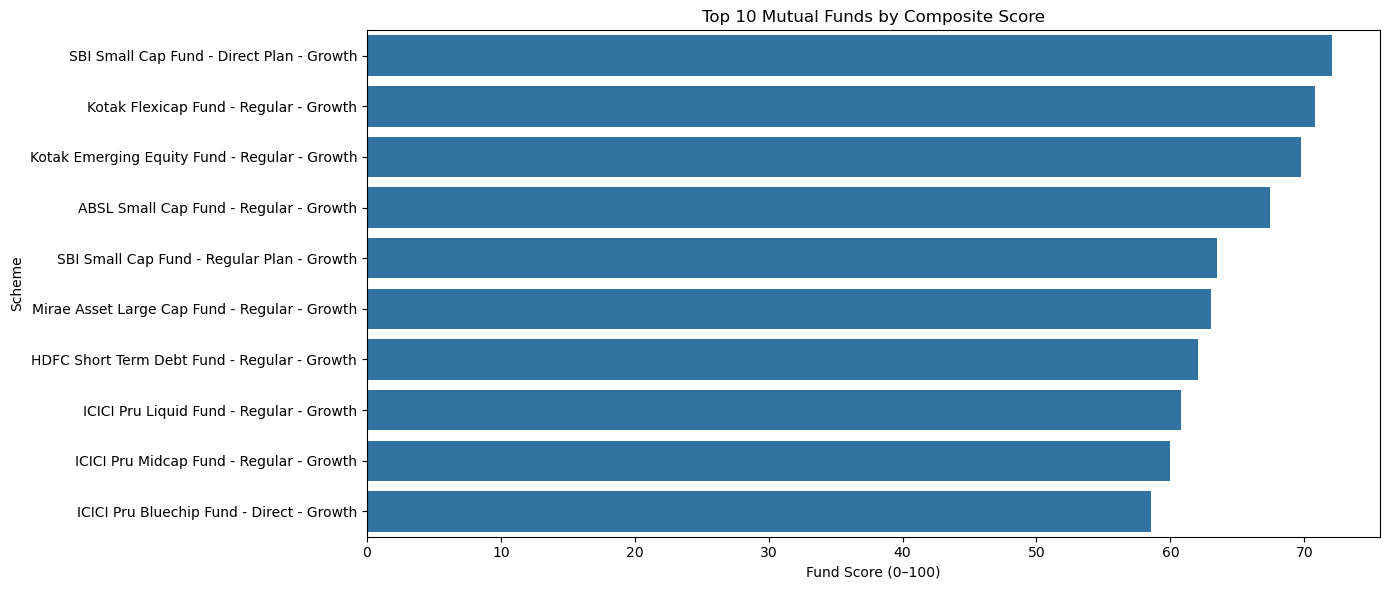

In [70]:
plt.figure(figsize=(14,6))

sns.barplot(
    data=scorecard.head(10),
    x="Fund_Score",
    y="scheme_name"
)

plt.title("Top 10 Mutual Funds by Composite Score")
plt.xlabel("Fund Score (0–100)")
plt.ylabel("Scheme")

plt.tight_layout()

plt.savefig(
    "../reports/fund_scorecard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Key Insight

The composite fund score combines return, risk-adjusted performance, alpha generation, expense efficiency, and downside protection into a single ranking. Funds with higher scores demonstrate stronger overall investment quality across multiple performance dimensions.


# 8. Benchmark Comparison and Tracking Error

## Objective

Compare the performance of the top 5 mutual funds against the Nifty 50 and Nifty 100 benchmarks over the analysis period. Additionally, compute the annualized tracking error to measure how closely each fund follows its benchmark.

### Tracking Error Formula

Tracking Error = Standard Deviation(Fund Return − Benchmark Return) × √252


In [71]:
top5 = scorecard.head(5)

top5

,amfi_code,scheme_name,fund_house,return_3yr_pct,sharpe_ratio,alpha,expense_ratio_pct,max_drawdown_pct,Return_Rank,Sharpe_Rank,Alpha_Rank,Expense_Rank,Drawdown_Rank,Return_Score,Sharpe_Score,Alpha_Score,Expense_Score,Drawdown_Score,Fund_Score,Rank
3,119599,SBI Small Cap Fund - Direct Plan - Growth,SBI Mutual Fund,23.14,0.93,1.13,0.72,-24.78,2.0,19.5,22.5,5.5,11.0,97.435897,52.564103,44.871795,88.461538,74.358974,72.051282,1
22,120843,Kotak Flexicap Fund - Regular - Growth,Kotak Mahindra MF,15.65,0.98,1.85,1.45,-19.50,11.0,12.0,3.5,22.0,21.0,74.358974,71.794872,93.589744,46.153846,48.717949,70.769231,2
21,120842,Kotak Emerging Equity Fund - Regular - Growth,Kotak Mahindra MF,18.23,0.96,1.91,1.56,-21.92,7.0,15.0,2.0,33.0,16.0,84.615385,64.102564,97.435897,17.948718,61.538462,69.743590,3
29,101207,ABSL Small Cap Fund - Regular - Growth,Aditya Birla Sun Life MF,22.38,0.90,1.84,1.53,-23.61,3.0,24.5,5.0,28.5,14.0,94.871795,39.743590,89.743590,29.487179,66.666667,67.435897,4
2,119598,SBI Small Cap Fund - Regular Plan - Growth,SBI Mutual Fund,23.39,0.94,1.23,1.43,-13.35,1.0,18.0,20.0,21.0,33.0,100.000000,56.410256,51.282051,48.717949,17.948718,63.461538,5


In [72]:
benchmark["date"] = pd.to_datetime(benchmark["date"])

benchmark_plot = benchmark[
    benchmark["index_name"].isin(["NIFTY50", "NIFTY100"])
].copy()

benchmark_plot.head()

,date,index_name,close_value
0,2022-01-03,NIFTY50,17492.79
1,2022-01-04,NIFTY50,17689.64
2,2022-01-05,NIFTY50,17835.05
3,2022-01-06,NIFTY50,17878.51
4,2022-01-07,NIFTY50,17759.15


In [74]:
benchmark_plot["Normalized"] = benchmark_plot.groupby(
    "index_name"
)["close_value"].transform(
    lambda x: x / x.iloc[0] * 100
)

In [75]:
top5_nav = nav[
    nav["amfi_code"].isin(top5["amfi_code"])
].copy()

top5_nav = top5_nav.merge(
    scheme[["amfi_code", "scheme_name"]],
    on="amfi_code"
)

top5_nav["Normalized"] = top5_nav.groupby(
    "scheme_name"
)["nav"].transform(
    lambda x: x / x.iloc[0] * 100
)

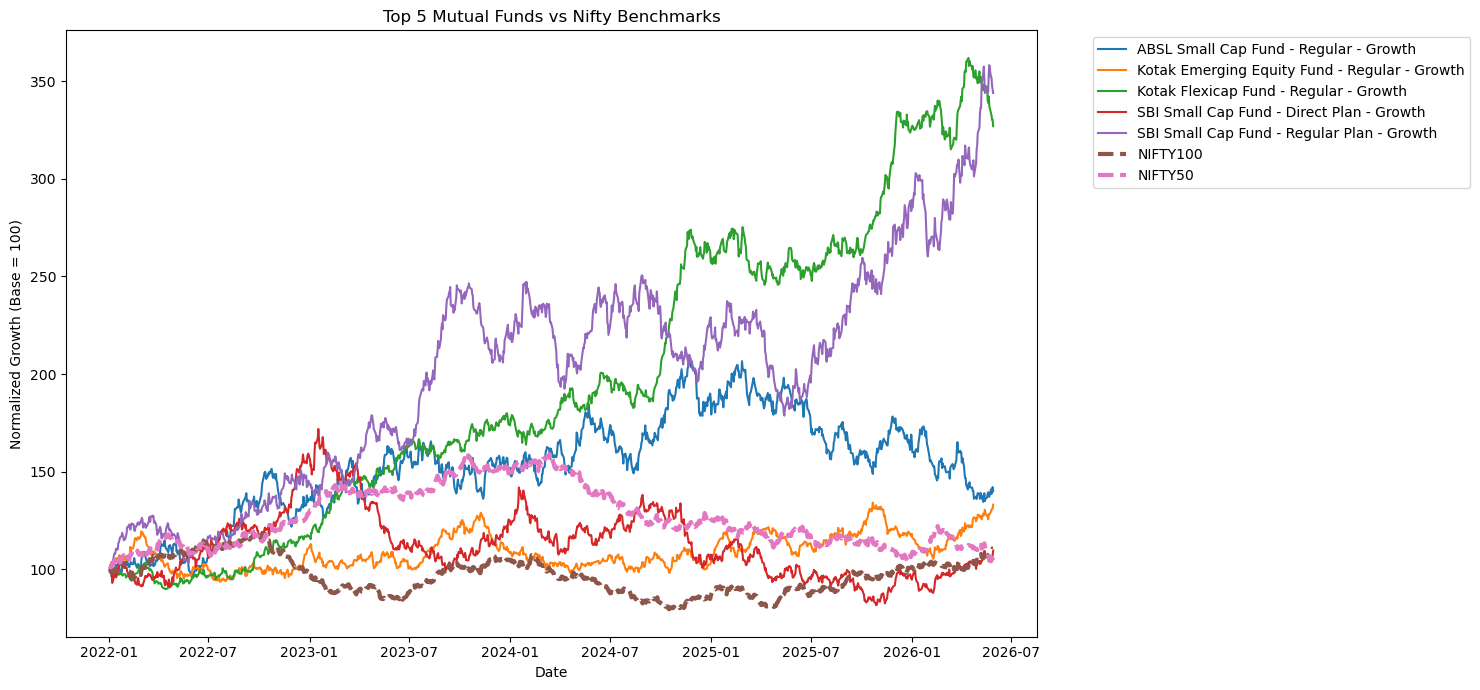

In [76]:
plt.figure(figsize=(15,7))

# Plot Top 5 Funds
for name, data in top5_nav.groupby("scheme_name"):
    plt.plot(
        data["date"],
        data["Normalized"],
        label=name
    )

# Plot Benchmarks
for name, data in benchmark_plot.groupby("index_name"):
    plt.plot(
        data["date"],
        data["Normalized"],
        linewidth=3,
        linestyle="--",
        label=name
    )

plt.title("Top 5 Mutual Funds vs Nifty Benchmarks")
plt.xlabel("Date")
plt.ylabel("Normalized Growth (Base = 100)")
plt.legend(bbox_to_anchor=(1.05, 1))
plt.tight_layout()

plt.savefig(
    "../reports/benchmark_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [77]:
tracking_error = []

# NIFTY100 daily returns
benchmark_returns = benchmark[
    benchmark["index_name"] == "NIFTY100"
].copy()

benchmark_returns = benchmark_returns.sort_values("date")

benchmark_returns["benchmark_return"] = (
    benchmark_returns["close_value"].pct_change()
)

for fund in top5["amfi_code"]:

    fund_data = nav[
        nav["amfi_code"] == fund
    ][["date", "daily_return"]]

    merged = pd.merge(
        fund_data,
        benchmark_returns[
            ["date", "benchmark_return"]
        ],
        on="date"
    ).dropna()

    te = (
        (merged["daily_return"] -
         merged["benchmark_return"]).std()
        * np.sqrt(252)
    )

    tracking_error.append(
        {
            "amfi_code": fund,
            "Tracking_Error": te
        }
    )

tracking_error = pd.DataFrame(tracking_error)

tracking_error

,amfi_code,Tracking_Error
0,119599,0.277135
1,120843,0.206425
2,120842,0.219169
3,101207,0.292117
4,119598,0.283881


In [78]:
tracking_error.to_csv(
    "../reports/tracking_error.csv",
    index=False
)

## Key Insight

The benchmark comparison illustrates how the top-performing mutual funds have performed relative to the Nifty 50 and Nifty 100 indices. Tracking Error quantifies the consistency of a fund's returns relative to the benchmark, with lower values indicating closer benchmark tracking and higher values reflecting more active portfolio management.
